# Bitcoin: what if we traded on the forecasts? — Filip

`v3-extensions.ipynb` found two things that are predictable:
1. the **direction of the next hour** (AUC 0.537, 55% correct on the most confident 10%),
2. the **size of the moves** (R² ≈ 0.15 with monthly refitting).

This notebook puts **10,000 USD** on each of them over Alberto's test block (Jul 2024 → Oct 2026) and compares with simply buying and holding Bitcoin.

**Costs.** A fee is paid on every change of the position, proportional to its size:

| Scenario | Fee per side | Corresponds to |
|---|---|---|
| Spot | 0.10% | Binance spot, standard taker fee |
| Cheap | 0.02% | Binance futures maker fee (limit orders) |
| No fees | 0% | the theoretical, gross result |

Not modelled (all of them would make the results *worse*): slippage, the bid-ask spread, funding costs of short positions, taxes. Every setting is fixed in advance or chosen on the validation block; all variants are reported.

## 1. Setup

In [1]:
from shared_cells import run_shared_cells

run_shared_cells(globals(), "v3")

from binance_features import load_binance, build_attributes

btc, eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
groups = build_attributes(btc, eth)
FEAT = pd.concat([FEAT] + [t.reindex(hourly.index) for t in groups.values()], axis=1)   # Xl() / Xw() read FEAT
ALL_COLS = BASE + sum((list(t.columns) for t in groups.values()), [])

CAPITAL = 10_000
FEES = {"Spot (0.10%)": 0.001, "Cheap (0.02%)": 0.0002, "No fees": 0.0}

def simulate(position, returns, fee):
    # position: fraction of capital in BTC for each period (−1 = short); returns: BTC return of each period
    position = np.asarray(position, float)
    turnover = np.abs(np.diff(np.r_[0, position]))
    net = position * returns - turnover * fee
    return CAPITAL * np.cumprod(1 + net), turnover.sum()

def summary(equity, periods_per_year, trades):
    r = np.diff(np.r_[CAPITAL, equity]) / np.r_[CAPITAL, equity[:-1]]
    return {"final USD": equity[-1], "return %": (equity[-1] / CAPITAL - 1) * 100,
            "Sharpe": r.mean() / r.std() * np.sqrt(periods_per_year) if r.std() > 0 else 0,
            "max drawdown %": (equity / np.maximum.accumulate(equity) - 1).min() * 100, "trades": trades}

hourly series 2012-01-01 01:00:00 -> 2026-10-04 02:00:00 | features: base 42, B1 7, B2 6, B3 5 (per hour)
  train   7149 origins  2018-01-30 -> 2022-12-22
  val     2156 origins  2022-12-31 -> 2024-06-21
  test   19827 origins  2024-06-30 -> 2026-10-04


## 2. Strategy A: trade the direction of the next hour

Every hour, the Gradient Boosting classifier of `v3-extensions.ipynb` section 5 (base + Binance attributes) gives the probability that the next hour goes up. We trade **only when it is confident**: when the probability is far enough from its median. "Top 10%" means the threshold that the 10% most confident forecasts exceeded **on the validation block** (model fitted on train), so the threshold is fixed before the test.

- **Long/short:** +1 (buy) if it expects up, −1 (short) if it expects down, 0 otherwise. Needs futures or margin.
- **Long only:** +1 or 0, possible on spot.
- **Reversal rule:** every hour, the opposite of the last hour's move (no model).

In [2]:
y1 = {k: Y[k][:, 0] for k in P}
make_clf = lambda: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, learning_rate=0.03, max_depth=3,
                                                  min_samples_leaf=200, random_state=RANDOM_STATE)   # setting chosen in v3-extensions
p_val = make_clf().fit(Xw("train", ALL_COLS), y1["train"] > 0).predict_proba(Xw("val", ALL_COLS))[:, 1]
p_test = make_clf().fit(np.vstack([Xw("train", ALL_COLS), Xw("val", ALL_COLS)]),
                        np.r_[y1["train"], y1["val"]] > 0).predict_proba(Xw("test", ALL_COLS))[:, 1]
r_hour = y1["test"] / 100                                   # BTC return of the next hour, every test hour

centre = np.median(p_val)
strategies_a = {"Buy and hold": np.ones_like(r_hour),
                "Reversal rule, every hour": -np.sign(FEAT["ret_lag1"].values[P["test"]])}
for top in (0.5, 0.2, 0.1, 0.05, 0.01):
    th = np.quantile(np.abs(p_val - centre), 1 - top)
    signal = np.where(p_test - centre > th, 1, np.where(p_test - centre < -th, -1, 0))
    strategies_a[f"Model top {top:.0%}, long/short"] = signal
    strategies_a[f"Model top {top:.0%}, long only"] = np.maximum(signal, 0)

rows, equity_a = [], {}
for fee_name, fee in FEES.items():
    for name, pos in strategies_a.items():
        eq, trades = simulate(pos, r_hour, fee)
        equity_a[fee_name, name] = eq
        rows.append({"fees": fee_name, "strategy": name, "hours in market %": np.mean(pos != 0) * 100,
                     **summary(eq, 24 * 365, trades)})
tab_a = pd.DataFrame(rows)
display(tab_a.pivot(index="strategy", columns="fees", values="final USD")[list(FEES)]
        .loc[list(strategies_a)].style.format("{:,.0f}").background_gradient(cmap="RdYlGn", axis=None))
display(tab_a[tab_a.fees == "Spot (0.10%)"].drop(columns="fees").set_index("strategy").round(2))

fees,Spot (0.10%),Cheap (0.02%),No fees
strategy,,,
Buy and hold,"13,911","13,922","13,925"
"Reversal rule, every hour",0,214,"13,211"
"Model top 50%, long/short",0,"1,824","18,992"
"Model top 50%, long only",53,"4,455","13,471"
"Model top 20%, long/short",32,"4,687","16,288"
"Model top 20%, long only",767,"7,024","12,213"
"Model top 10%, long/short",409,"6,893","13,960"
"Model top 10%, long only","2,810","9,576","13,009"
"Model top 5%, long/short","1,331","7,598","11,741"


,hours in market %,final USD,return %,Sharpe,max drawdown %,trades
strategy,,,,,,
Buy and hold,100.00,13911.10,39.11,0.55,-53.84,1.0
"Reversal rule, every hour",100.00,0.00,-100.00,-18.82,-100.00,20611.0
"Model top 50%, long/short",50.18,0.15,-100.00,-13.79,-100.00,11714.0
"Model top 50%, long only",22.64,53.18,-99.47,-9.75,-99.47,5532.0
"Model top 20%, long/short",21.43,32.05,-99.68,-10.38,-99.68,6228.0
"Model top 20%, long only",9.09,767.44,-92.33,-7.33,-92.34,2766.0
"Model top 10%, long/short",11.14,409.19,-95.91,-7.54,-95.93,3528.0
"Model top 10%, long only",4.58,2809.64,-71.90,-4.88,-71.90,1532.0
"Model top 5%, long/short",6.51,1331.09,-86.69,-6.65,-86.75,2176.0


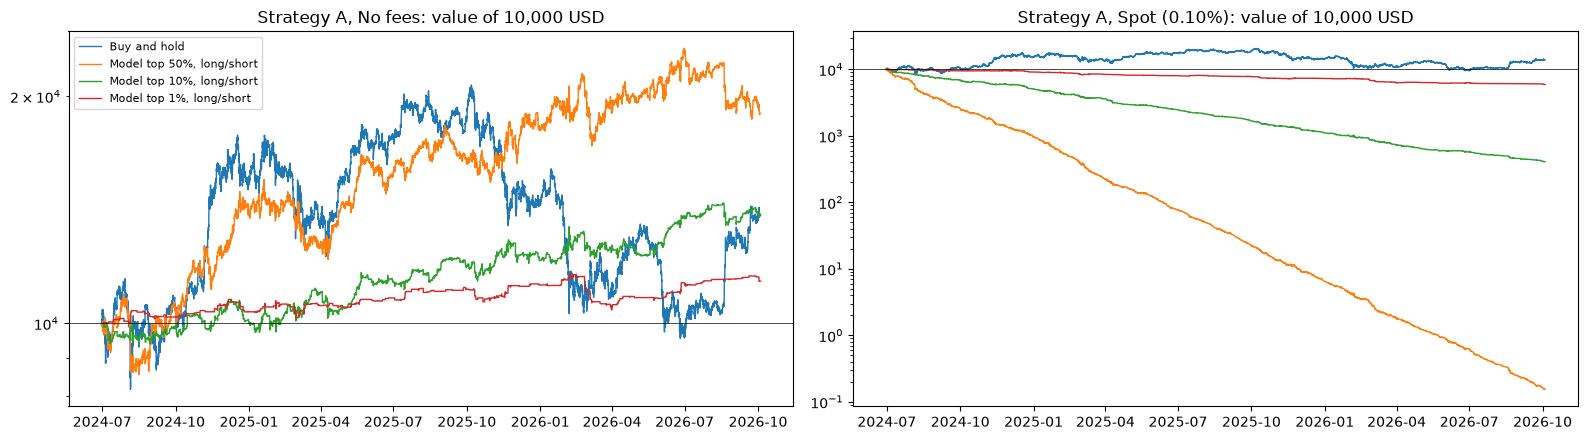

Model top 50%, long/short: gross gain per unit traded 0.0055% -> break-even fee ≈ 0.0055% per side
Model top 10%, long/short: gross gain per unit traded 0.0095% -> break-even fee ≈ 0.0095% per side
Model top 1%, long/short: gross gain per unit traded 0.0198% -> break-even fee ≈ 0.0198% per side


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
show = ["Buy and hold", "Model top 50%, long/short", "Model top 10%, long/short", "Model top 1%, long/short"]
t = D["test"] + pd.Timedelta(hours=1)
for a, fee_name in zip(ax, ["No fees", "Spot (0.10%)"]):
    for name in show:
        a.plot(t, equity_a[fee_name, name], lw=1, label=name)
    a.set_yscale("log"); a.set_title(f"Strategy A, {fee_name}: value of 10,000 USD"); a.axhline(CAPITAL, c="k", lw=0.5)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# How low would the fee have to be for the model to break even?
g = tab_a.query("fees == 'No fees'").set_index("strategy")
for name in ["Model top 50%, long/short", "Model top 10%, long/short", "Model top 1%, long/short"]:
    gain_per_trade = np.log(g.loc[name, "final USD"] / CAPITAL) / g.loc[name, "trades"]
    print(f"{name}: gross gain per unit traded {gain_per_trade * 100:.4f}% -> break-even fee ≈ {gain_per_trade * 100:.4f}% per side")

**What we see.**
- **Without fees the direction signal is real:** long/short on the top 50% turns 10,000 USD into **18,992 USD**, more than buy and hold (13,925), while being in the market only half of the time.
- **With fees it destroys the account.** Spot fees (0.10%): every model variant loses, from −17% (top 1%, long only) to −100% (top 50%). Even with the cheapest fees (0.02%), no variant ends above 10,000 USD.
- **Why:** the model's edge is about **0.005–0.02% per trade**, and the fee is 0.02–0.10% per trade. The break-even fee (printed above) is below anything a retail trader can get; the spread and slippage, which are not even modelled, cost more than that alone.
- Trading only the most confident hours raises the edge per trade (0.0055% → 0.0198%), but the number of trades falls faster than the costs, and the gross profit becomes smaller than buy and hold.

## 3. Strategy B: hold less Bitcoin when big moves are expected (volatility targeting)

The move-size forecast cannot say *where* the price goes, but it can say *how risky* the next day is. A standard use is **volatility targeting**: every day at 00:00 UTC, hold `target / predicted volatility` of the capital in Bitcoin, so the position shrinks before wild days and grows before calm ones.

- Predicted volatility = average predicted |hourly move| over the next 24 hours, from Gradient Boosting refitted every month with a 12-month half-life (the best variant of `v3-extensions.ipynb`).
- `target` = the median predicted volatility on the validation block, so a typical day has a position of 1.
- Maximum position 1 (no borrowing) or 2 (up to 2× leverage). The position is only changed when it moves by more than 0.1 (fewer trades).
- **Simple rule for comparison:** the same with last week's average |hourly move| instead of the model.

,average position,final USD,return %,Sharpe,max drawdown %,trades
strategy,,,,,,
Buy and hold,1.000,13788.988,37.890,0.538,-53.077,1.000
"Vol target (model), max 1x",0.854,10586.480,5.865,0.248,-50.045,57.949
"Vol target (model), max 2x",1.023,11065.425,10.654,0.309,-51.503,203.704
"Vol target (last week), max 1x",0.858,11985.554,19.856,0.401,-49.620,13.463
"Vol target (last week), max 2x",0.987,13250.270,32.503,0.504,-53.660,28.653


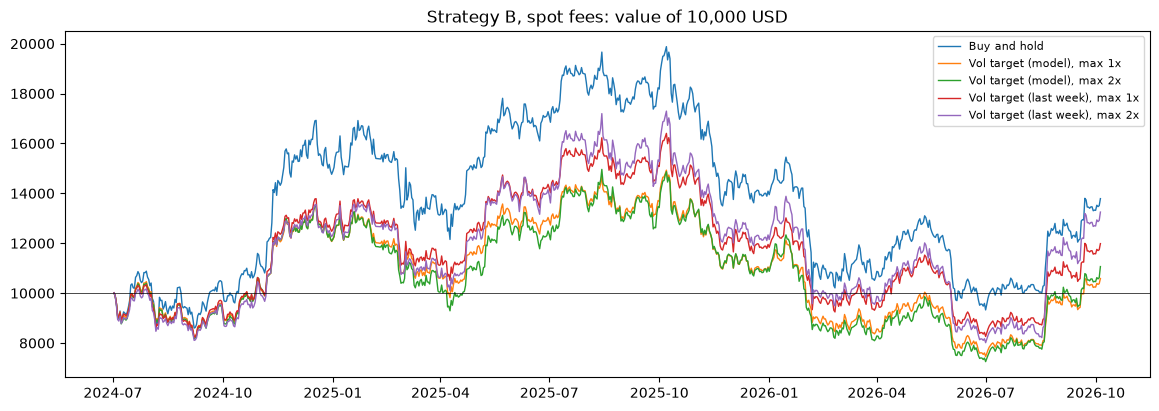

In [4]:
HC = H_BASE + B3
make_gb = lambda: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, min_samples_leaf=1000, learning_rate=0.1,
                                                max_depth=3, random_state=RANDOM_STATE)
day_end = origins + pd.Timedelta(hours=24)
pool = np.flatnonzero(origins - pd.Timedelta(hours=U.MONTH - 1) >= DATA_START)[::STRIDE]
P["pool"], Y["pool"] = pos_all[pool], y_all[pool]
X_pool, y_pool = Xl("pool", BASE, HC), yl("pool")
pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)

# one origin per day: 23:00, so the 24 predicted hours are 00:00-23:00 of the next day
midnight = (origins + pd.Timedelta(hours=1)).hour == 0
for block, lo, hi in [("val_day", VAL_START, TEST_START - WINDOW), ("test_day", TEST_START, day_end[-1] + pd.Timedelta(hours=1))]:
    sel = np.flatnonzero(midnight & (day_end >= lo) & (day_end < hi))
    P[block], Y[block], D[block] = pos_all[sel], y_all[sel], origins[sel]

def predicted_day_vol(block, half_life=12):
    X, org = Xl(block, BASE, HC), np.repeat(D[block], 24)
    pred = np.empty(len(X))
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit = pool_end < start
        w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life)
        rows_m = (org >= start) & (org < (m + 1).start_time)
        pred[rows_m] = make_gb().fit(X_pool[fit], y_pool[fit], sample_weight=w).predict(X[rows_m])
    return pred.reshape(-1, 24).mean(axis=1)

abs_r = np.abs(hourly["Return"].values)
last_week_vol = lambda block: np.array([abs_r[p - 167: p + 1].mean() for p in P[block]])
vol_forecasts = {"model": (predicted_day_vol("val_day"), predicted_day_vol("test_day")),
                 "last week": (last_week_vol("val_day"), last_week_vol("test_day"))}
r_day = np.prod(1 + Y["test_day"] / 100, axis=1) - 1         # BTC return of each test day

def with_band(target_position, band=0.1):
    pos, current = np.empty(len(target_position)), 0.0
    for i, p in enumerate(target_position):
        if abs(p - current) > band:
            current = p
        pos[i] = current
    return pos

strategies_b = {"Buy and hold": np.ones(len(r_day))}
for name, (f_val, f_test) in vol_forecasts.items():
    for cap in (1, 2):
        strategies_b[f"Vol target ({name}), max {cap}x"] = with_band(np.clip(np.median(f_val) / f_test, 0, cap))

rows, equity_b = [], {}
for fee_name, fee in FEES.items():
    for name, pos in strategies_b.items():
        eq, trades = simulate(pos, r_day, fee)
        equity_b[fee_name, name] = eq
        rows.append({"fees": fee_name, "strategy": name, "average position": pos.mean(), **summary(eq, 365, trades)})
tab_b = pd.DataFrame(rows)
display(tab_b[tab_b.fees == "Spot (0.10%)"].drop(columns="fees").set_index("strategy").round(3))

fig, ax = plt.subplots(figsize=(14, 4.5))
for name in strategies_b:
    ax.plot(D["test_day"] + pd.Timedelta(days=1), equity_b["Spot (0.10%)", name], lw=1, label=name)
ax.axhline(CAPITAL, c="k", lw=0.5); ax.set_title("Strategy B, spot fees: value of 10,000 USD"); ax.legend(fontsize=8)
plt.show()

**What we see.**
- **Volatility targeting does not beat buy and hold here:** with the model, 10,000 USD become 10,586–11,065 USD (Sharpe 0.25–0.31), buy and hold 13,789 USD (Sharpe 0.54). The maximum drawdown is barely smaller (−50% vs −53%).
- **The simple "last week" rule is better than the model** (13,251 USD, Sharpe 0.50 at max 2×). The model reacts to short-term volatility more, so it changes the position more often (204 vs 29 units traded at max 2×) and pays more fees; and holding less on wild days also means missing part of the big up-moves, which in a rising market costs more than the avoided losses save.
- A better R² for hourly volatility (section 3 of `v3-extensions.ipynb`) does not automatically mean a better daily investment rule.

## 4. Conclusions

Run on 11 October 2026, test block 1 Jul 2024 → 4 Oct 2026, starting capital 10,000 USD.

| Strategy | With spot fees (0.10%) | Without fees |
|---|---|---|
| **Buy and hold** | **13,911 USD (+39%)** | 13,925 USD |
| Next-hour direction, best variant (top 1%, long only) | 8,275 USD (−17%) | 10,375 USD |
| Next-hour direction, most active (top 50%, long/short) | 0 USD (−100%) | 18,992 USD (+90%) |
| Volatility targeting with the model (max 2×) | 11,065 USD (+11%) | — |
| Volatility targeting with last week's volatility (max 2×) | 13,250 USD (+33%) | — |

**With real money, none of the forecasts would have made a profit beyond simply holding Bitcoin.**
- The **direction** signal is statistically real (it makes money before costs), but it is about 5–20× smaller than the trading fees. It is a nice result for the report ("a measurable inefficiency that costs eliminate"), not a trading strategy.
- The **size** forecast is useful for describing risk (ranges, calm vs wild hours), but as a daily position-sizing rule it did not beat buy and hold or even the simple volatility rule in this period.

Caveats: one test period (2¼ years, Bitcoin +39%); no spread, slippage, short-funding costs or taxes, which would all make the active strategies worse.